# Gold Standard Creation - Wikidata x OurAirports

In [1]:
import pandas as pd 
import random
import math
import matplotlib.pyplot as plt
from pathlib import Path
from PyDI.io import load_csv

from PyDI.entitymatching import TokenBlocker, RuleBasedMatcher, BaseComparator, StringComparator
from collections import Counter
import h3

from sklearn.model_selection import StratifiedKFold

/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Workflow

1. **Load data** (Wikidata, OurAirports) and set the random seed.
2. **Positive cases**
   - ICAO positives: pairs with the same valid ICAO code. Merge both sources on `icao` and score every pair with the weighted similarity (`name`, `geo_distance`, `city`). Remove pairs that are very likely not the same airport despite the same ICAO: distance > 50 km, or both IATA codes present and different.
     - Hard positives: the 250 lowest-scoring pairs of the cleaned set.
     - Normal positives: 250 pairs drawn at random from the remaining cleaned pairs.
   - Code-changed positives: pairs with a **different** ICAO but the **same** IATA code (and within 50 km), found while inspecting the negatives. The airport most likely changed its ICAO code, so these are matches that the ICAO merge cannot find. They are a separate group.
3. **Negative cases** (pairs with different valid ICAO codes)
   - Blocking (Rule A: `countryCode` + distinguishing `name` token, Rule B: H3 grid), union and de-duplication give the candidate pairs.
   - Keep only candidates with a valid ICAO on both sides that differs, and score them with the same weighted similarity.
   - Pairs with the same IATA code leave the pool (see code-changed positives). Pairs less than 3 km apart and pairs with identical names less than 10 km apart are dropped, because they are likely the same airport.
   - Hard negatives, selected only from pairs with a known distance: 125 pairs with the most similar `name` plus 125 pairs that are closest to each other (at least 3 km apart).
   - Normal negatives: 250 pairs drawn at random from the remaining pool.
4. **Consistency cleanup**: each Wikidata and OurAirports record may appear in at most one positive. Positives that collide with a code-changed pair, and positives whose record sits at another OA airport (relocated airports), are removed and back-filled to 250 pairs.
5. **Checks**: no pair appears in more than one group; manual inspection of hard positives, code-changed positives and hard negatives.
6. **Split and save**: stratified by group type into test (30 %) and train/validation (70 %), with 5 stratified folds on the train/validation part. Everything is written to one CSV with `split` and `fold` columns.


In [2]:
DATA_DIR = Path("../../../data/normalized_outputs")
OUTPUT_DIR = Path("../../../data/identity_resolution/gold_standard")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WIKIDATA_FILE = DATA_DIR / "wikidataNormalized.csv"
OURAIRPORT_FILE = DATA_DIR / "ourairportsNormalized.csv"

df_wd = load_csv(WIKIDATA_FILE, name="wikidata")
df_wd.attrs['source'] = 'wikidata'

df_oa = load_csv(OURAIRPORT_FILE, name="ourairports")
df_oa.attrs['source'] = 'ourairports'

print("===================================== \nWikidata\n===================================== ")
print(f"Loaded {len(df_wd)} records")
print(f"Columns: {list(df_wd.columns)}")
display(df_wd.head(3))

print("===================================== \nOurAirports\n===================================== ")
print(f"Loaded {len(df_oa)} records")
print(f"Columns: {list(df_oa.columns)}")
display(df_oa.head(3))

Wikidata
Loaded 24859 records
Columns: ['id', 'name', 'iata', 'icao', 'lat', 'lon', 'elevation', 'countryName', 'city', 'wikidataURI', 'operator', 'timezone', 'owner', 'localCode', 'countryCode']


,id,name,iata,icao,lat,lon,elevation,countryName,city,wikidataURI,operator,timezone,owner,localCode,countryCode
0,wd_1,jian jinggangshan airport,JGS,ZSGS,26.857500,114.737222,86.0000,peoples republic of china,taihe county,http://www.wikidata.org/entity/Q1000018,NaN,NaN,NaN,NaN,CN
1,wd_2,changde taohuayuan airport,CGD,ZGCD,28.918900,111.640000,NaN,peoples republic of china,hunan,http://www.wikidata.org/entity/Q1000025,NaN,NaN,NaN,NaN,CN
2,wd_3,jiujiang lushan airport,JIU,ZSJJ,29.476944,115.801111,49.9872,peoples republic of china,jiujiang,http://www.wikidata.org/entity/Q1002604,NaN,NaN,NaN,NaN,CN


OurAirports
Loaded 86151 records
Columns: ['id', 'name', 'type', 'scheduledService', 'localCode', 'lat', 'lon', 'elevation', 'countryCode', 'isoRegion', 'city', 'runway_lengthFt', 'runway_widthFt', 'runway_surface', 'runway_lighted', 'runway_closed', 'runway_leIdent', 'runway_heIdent', 'wikipedia', 'continent', 'iata', 'icao', 'countryName']


,id,name,type,scheduledService,localCode,lat,lon,elevation,countryCode,isoRegion,...,runway_surface,runway_lighted,runway_closed,runway_leIdent,runway_heIdent,wikipedia,continent,iata,icao,countryName
0,oa_1,total rf heliport,heliport,False,00A,40.070985,-74.933689,3.3528,US,US-PA,...,ASPH-G,false,false,H1,NaN,NaN,NaN,NaN,NaN,united states
1,oa_2,aero b ranch airport,small_airport,False,00AA,38.704022,-101.473911,1046.9880,US,US-KS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,united states
2,oa_3,lowell field,small_airport,False,00AK,59.947733,-151.692524,137.1600,US,US-AK,...,GRVL,false,false,N,S,NaN,NaN,NaN,NaN,united states


### Set random seed

In [3]:
SEED = 1234
random.seed(SEED)

## Positive Pairs (Matches)

### Clean Data and Merge with ICAO

In [4]:
valid_icao = r"^[A-Z0-9]{4}$"

wd_valid = df_wd[df_wd["icao"].astype(str).str.match(valid_icao, na=False)]
oa_valid = df_oa[df_oa["icao"].astype(str).str.match(valid_icao, na=False)]

true_pairs = pd.merge(
    wd_valid, 
    oa_valid, 
    on="icao", 
    how="inner", 
    suffixes=("_wd", "_oa")
)

display(true_pairs.head(3))

candidates_true = (
    true_pairs
        .rename(
            columns = {"id_wd": "id1", "id_oa": "id2"}
        )
)


,id_wd,name_wd,iata_wd,icao,lat_wd,lon_wd,elevation_wd,countryName_wd,city_wd,wikidataURI,...,runway_widthFt,runway_surface,runway_lighted,runway_closed,runway_leIdent,runway_heIdent,wikipedia,continent,iata_oa,countryName_oa
0,wd_1,jian jinggangshan airport,JGS,ZSGS,26.857500,114.737222,86.0000,peoples republic of china,taihe county,http://www.wikidata.org/entity/Q1000018,...,NaN,Concrete,false,false,08,26,https://en.wikipedia.org/wiki/Ji%27an_Jinggang...,AS,JGS,china
1,wd_2,changde taohuayuan airport,CGD,ZGCD,28.918900,111.640000,NaN,peoples republic of china,hunan,http://www.wikidata.org/entity/Q1000025,...,NaN,NaN,false,false,02,20,https://en.wikipedia.org/wiki/Changde_Taohuayu...,AS,CGD,china
2,wd_3,jiujiang lushan airport,JIU,ZSJJ,29.476944,115.801111,49.9872,peoples republic of china,jiujiang,http://www.wikidata.org/entity/Q1002604,...,165,CON,false,false,04,22,https://en.wikipedia.org/wiki/Jiujiang_Lushan_...,AS,JIU,china


### Run comparators to get the weighted similarity score

#### Define and instantiate comparators

In [5]:
# name: tolerant of small spelling differences
name_comp = StringComparator(column="name", similarity_function="jaro_winkler")

# city: same metric, weighted lower later (see markdown above)
city_comp = StringComparator(column="city", similarity_function="jaro_winkler")

# lat/lon: great-circle (Haversine) distance between the two points, not two
# independent degree-difference comparators (see markdown above for why).
class GeoDistanceComparator(BaseComparator):
    """Great-circle (Haversine) distance between two lat/lon points, converted to similarity."""

    def __init__(self, lat_column="lat", lon_column="lon", max_distance_km=10.0):
        super().__init__(name="geo_distance")
        self.lat_column = lat_column
        self.lon_column = lon_column
        self.max_distance_km = max_distance_km

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
            return 0.5  # neutral: can't compute without both coordinates
        distance_km = self._haversine_km(lat1, lon1, lat2, lon2)
        return max(0.0, 1.0 - distance_km / self.max_distance_km)

    @staticmethod
    def _haversine_km(lat1, lon1, lat2, lon2):
        R = 6371.0  # Earth radius in km
        phi1, phi2 = math.radians(lat1), math.radians(lat2)
        dphi = math.radians(lat2 - lat1)
        dlambda = math.radians(lon2 - lon1)
        a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
        return 2 * R * math.asin(math.sqrt(a))

geo_comp = GeoDistanceComparator(max_distance_km=2.0)


# * ------
# Quick sanity check: compare the first candidate pair field by field
comparators = [name_comp, geo_comp, city_comp]
comparator_names = ["name", "geo_distance", "city"]

row = candidates_true.iloc[0]
r1 = df_wd.set_index("id").loc[row["id1"]]
r2 = df_oa.set_index("id").loc[row["id2"]]
for cname, comp in zip(comparator_names, comparators):
    print(f"  {cname:<12} -> {comp.compare(r1, r2):.2f}")

  name         -> 0.88
  geo_distance -> 0.96
  city         -> 0.39


### Score candidates with `RuleBasedMatcher`

Goal: combine the per-attribute scores into one similarity score per candidate pair. The score is used only to rank pairs when selecting the hard cases (lowest-scoring positives, highest-scoring negatives).

Method: weighted sum of three comparator scores. The weights sum to 1.0, so the final score lies in [0, 1].

| Attribute | Weight | Rationale |
|---|---|---|
| `name` | 0.50 | Most discriminative attribute available for almost every record |
| `geo_distance` | 0.35 | The same airport has (nearly) the same coordinates in every source (`max_distance_km=2.0`) |
| `city` | 0.15 | Lowest: in Wikidata it is often a county or state rather than a real city |

`icao` and `iata` are left out. The labels are derived from `icao` (pairs with the same ICAO are positives, pairs with different ICAO are negatives), so using it as a feature would leak the label into the score and make the hardness ranking meaningless.

`threshold=0.0` keeps every candidate pair, because the scores are used for ranking and no cutoff is applied here.


- Scored 7758 candidate pairs


,id1,id2,score,notes
0,wd_1,oa_19599,0.836020,comparators=3
1,wd_2,oa_85742,0.939249,comparators=3
2,wd_3,oa_85933,0.999991,comparators=3
3,wd_4,oa_86088,0.911287,comparators=3
4,wd_5,oa_86135,0.846871,comparators=3


count    7758.000000
mean        0.864251
std         0.108798
min         0.245202
25%         0.831091
50%         0.898331
75%         0.927898
max         1.000000
Name: score, dtype: float64

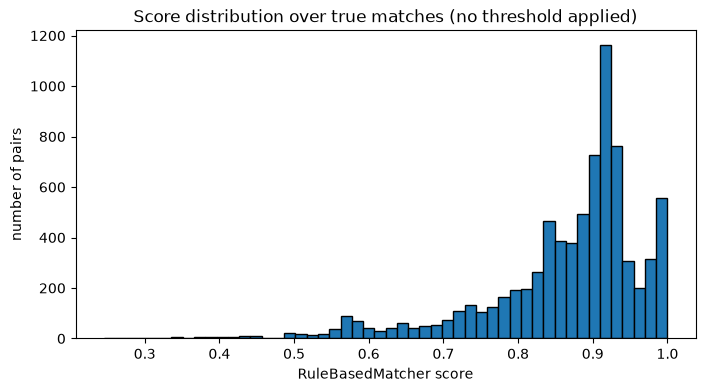

In [6]:
weights = [
    0.5,      # name
    0.35,     # geo_distance
    0.15      # city
]  

matcher = RuleBasedMatcher()
correspondences, debug_results = matcher.match(
    df_left = df_wd,
    df_right = df_oa,
    candidates = candidates_true,
    id_column = "id",
    comparators = comparators,
    weights = weights,
    threshold = 0.0,  # keep everything for now
    debug = True,
)

print(f"- Scored {len(correspondences)} candidate pairs")
display(correspondences.head(5))

display(correspondences["score"].describe())

# visualization
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correspondences["score"], bins = 50, edgecolor= "black")
ax.set_xlabel("RuleBasedMatcher score")
ax.set_ylabel("number of pairs")
ax.set_title("Score distribution over true matches (no threshold applied)")
plt.show()

### Generate the hard positives
Goal: pick the 250 positive pairs that are hardest to recognize as matches, i.e. pairs that are the same airport but look the least similar.

Method:
1. The true matches are the pairs with the same ICAO code (see above). Each pair already has a weighted similarity score from the `RuleBasedMatcher` (`name`, `geo_distance`, `city`).
2. ICAO codes in the sources are not always correct. A pair with a wrong ICAO is not a real match, and because it is dissimilar by construction, it would end up at the very bottom of the ranking. Before sorting we therefore remove pairs that are very likely not the same airport:
   - the two records are more than 50 km apart (in a manual check of the 20 lowest-scoring pairs, every correct pair was within 21 km and every wrong pair was more than 200 km apart), or
   - both records have an IATA code and the codes differ. Pairs without coordinates are kept, since the distance cannot be checked. `icao` and `iata` are only used here to clean the labels. They are not part of the similarity score, so the score does not leak the label.


3. The remaining pairs are sorted by score in ascending order and the first 250 are taken as **hard positives**.
4. The **normal positives** are 250 pairs drawn at random from the remaining cleaned pairs (without the hard positives), using a fixed random seed.
5. Further positives are removed later in the *Consistency cleanup* section (relocated airports and pairs that collide with a code-changed positive). The hard and normal positives are then back-filled, so the groups keep 250 pairs.


In [7]:
attrs_wd = df_wd.set_index("id")[["lat", "lon", "iata"]].add_suffix("_wd")
attrs_oa = df_oa.set_index("id")[["lat", "lon", "iata"]].add_suffix("_oa")

pos = (
    correspondences
        .join(attrs_wd, on="id1")
        .join(attrs_oa, on="id2")
)

coords = ["lat_wd", "lon_wd", "lat_oa", "lon_oa"]
pos[coords] = pos[coords].apply(pd.to_numeric, errors="coerce")

pos["dist_km"] = [
    GeoDistanceComparator._haversine_km(a, b, c, d)
    for a, b, c, d in zip(pos["lat_wd"], pos["lon_wd"], pos["lat_oa"], pos["lon_oa"])
]

iata_conflict = (
    pos["iata_wd"].notna() & pos["iata_oa"].notna() & (pos["iata_wd"] != pos["iata_oa"])
)

# Remove (too distant, distance > 50 km) OR (different IATA) pairs
clean = pos[(pos["dist_km"].fillna(0) <= 50) & ~iata_conflict]
print(f"removed {len(pos) - len(clean)} suspicious positives")

# sort and get the head 250
hard_positives = (
    clean
        .sort_values("score", ascending=True)
        .head(250)
        .drop(columns=["notes"], errors="ignore")
        .copy()
)
hard_positives["type"] = "hard positive"
hard_positives["label"] = 1


removed 56 suspicious positives


### Manual check of the hard positives

Goal: verify by eye that the cleaned hard positives are really the same airport, and see what kind of "hard" they are.

Method: print the pairs side by side (name, city, country, ICAO, IATA, coordinates, distance) for the three lowest-scoring pairs and a few random ones from the rest.

In [8]:
SHOW_COLS = ["name", "city", "countryCode", "icao", "iata", "lat", "lon"]

def inspect_pairs(pairs, df_left, df_right, n=20, random_n=0, seed=SEED):
    cols_l = [c for c in SHOW_COLS if c in df_left.columns]
    cols_r = [c for c in SHOW_COLS if c in df_right.columns]
    shared = [c for c in cols_l if c in cols_r]

    left = df_left.set_index("id")[cols_l].add_suffix("_wd")
    right = df_right.set_index("id")[cols_r].add_suffix("_oa")

    view = (
        pairs[["id1", "id2", "score"]]
            .reset_index(drop=True)
            .join(left, on="id1")
            .join(right, on="id2")
    )
    coords = ["lat_wd", "lon_wd", "lat_oa", "lon_oa"]
    view[coords] = view[coords].apply(pd.to_numeric, errors="coerce")
    view["dist_km"] = [
        GeoDistanceComparator._haversine_km(a, b, c, d)
        for a, b, c, d in zip(view["lat_wd"], view["lon_wd"], view["lat_oa"], view["lon_oa"])
    ]


    shown = view.head(n)
    if random_n:
        shown = pd.concat([shown, view.iloc[n:].sample(min(random_n, len(view) - n), random_state=seed)])

    for _, r in shown.iterrows():
        print(f"score={r['score']:.3f}  dist={r['dist_km']:.1f} km  ({r['id1']} <-> {r['id2']})")
        for c in shared:
            print(f"  {c:12s} WD: {str(r[c + '_wd']):40s} OA: {r[c + '_oa']}")
        print()


inspect_pairs(hard_positives.sort_values("score"), df_wd, df_oa, n = 3, random_n = 1)

score=0.289  dist=2.8 km  (wd_5221 <-> oa_30703)
  name         WD: abdullahi yusuf international airport    OA: galcaio airport
  city         WD: mudug                                    OA: galcaio
  countryCode  WD: SO                                       OA: SO
  icao         WD: HCMR                                     OA: HCMR
  iata         WD: GLK                                      OA: GLK
  lat          WD: 6.766666934608                           OA: 6.78082991
  lon          WD: 47.43333308718                           OA: 47.45470047

score=0.307  dist=9.1 km  (wd_6251 <-> oa_28495)
  name         WD: wamba airport                            OA: kikongo sur wamba airport
  city         WD: democratic republic of the congo         OA: kikongo sur wamba
  countryCode  WD: CD                                       OA: CD
  icao         WD: FZCW                                     OA: FZCW
  iata         WD: nan                                      OA: nan
  lat          WD:


**Findings**:
- After the distance and IATA cleaning, every pair we inspected is the same airport: the coordinates are 1.8 to 9.1 km apart and the IATA code is identical wherever both sides have one.
- The pairs are hard because the names differ, not because the location differs. Typical reasons are a renamed airport (`abdullahi yusuf international airport` vs `galcaio airport`, `ilo airport` vs `general jorge fernandez maldon airport`) or a short vs long name (`wamba airport` vs `kikongo sur wamba airport`). A name comparator alone gives a low score here, while location and IATA are consistent.
- The random pair (`boundji airport`) has identical names and still falls in the pool, as expected: not every hard positive is dissimilar, only the lowest-scoring 250 are taken.

Limitation: only a few pairs were inspected after cleaning, so the remaining hard positives are not guaranteed to be free of label errors.


### Generate the normal positives
The **normal positives** are 250 pairs drawn at random from the remaining cleaned pairs (without the hard positives), using a fixed random seed.

In [9]:
normal_positives = (
    clean.drop(hard_positives.index)
         .sample(250, random_state = SEED)
         .drop(columns = ["notes"], errors = "ignore")
         .copy()
)
normal_positives["type"] = "normal positive"
normal_positives["label"] = 1

## Negative Pairs (Non-Matches)

### Blocking
Use blocking to find candidate pairs with different ICAO.
We use two blocking rules and concatenate the results:
- Blocking Rule A: `countryCode` + distinguishing `name` tokens
- Blocking Rule B: geographic grid (H3)

#### Rule A
- Goal: generate candidate pairs between Wikidata and OurAirports. Generic words in `name` (`airport`, `ranch`, common surnames, ...) and the unreliable Wikidata `city` field (often a state or province, not a real city) must not be used as blocking keys, because they would put thousands of unrelated records into the same block.

- Method: `TokenBlocker` on `name`.
  - A token is treated as non-distinguishing if it would create too many candidate pairs. The number of pairs a token creates is the number of Wikidata names containing it times the number of OurAirports names containing it, which is exactly the size of the block that token would produce. Tokens above `MAX_PAIRS_PER_TOKEN` are excluded. This list is derived from the data, not hand-picked.
  - `countryCode` is prepended to each remaining token (e.g. `"CN_jian"`), so a pair is a candidate only if the two records share a distinguishing token **and** have the same country.

- Limitation: records whose name has no distinguishing token left, or that have no `countryCode`, produce no tokens and cannot be found by this rule. Pairs whose `countryCode` differs between the two sources (e.g. sovereign state vs. overseas territory) are also missed. Both are covered by Rule B (geographic grid), whose candidates are combined with those of Rule A.


In [10]:
# Rule A: shared distinguishing name token, within the same country
# --------------------------------------------------------------
# A token is "common" if it would create too many candidate pairs.
# The number of pairs a token creates is (#WD names containing it) x (#OA names containing it),
# which is exactly the block size TokenBlocker would generate for it.

MAX_PAIRS_PER_TOKEN = 2000   # trade-off between block size and recall; tune with the debug CSV

def name_tokens(name):
    if not isinstance(name, str):
        return set()
    return {t for t in name.split() if len(t) >= 2}

doc_freq_wd = Counter(t for n in df_wd["name"] for t in name_tokens(n))
doc_freq_oa = Counter(t for n in df_oa["name"] for t in name_tokens(n))

COMMON_TOKENS = {
    t for t, c in doc_freq_wd.items()
    if c * doc_freq_oa.get(t, 0) > MAX_PAIRS_PER_TOKEN
}
print(f"Excluding {len(COMMON_TOKENS)} tokens that would each create more than "
      f"{MAX_PAIRS_PER_TOKEN} candidate pairs")

# The tokenizer only sees one column, so country and name are packed into one string.
def add_name_with_country(d):
    d = d.copy()
    d["name_with_country"] = d["countryCode"].fillna("") + "|" + d["name"].fillna("")
    return d

wd_blk = add_name_with_country(df_wd)
oa_blk = add_name_with_country(df_oa)

def country_scoped_tokenizer(text):
    if not isinstance(text, str) or "|" not in text:
        return []
    country, name = text.split("|", 1)
    if not country:          # Rule A needs a country code
        return []
    return [f"{country}_{t}" for t in name.split()
            if len(t) >= 2 and t not in COMMON_TOKENS]

blocker_token = TokenBlocker(
    df_left=wd_blk,
    df_right=oa_blk,
    column="name_with_country",
    id_column="id",
    tokenizer=country_scoped_tokenizer,
)

candidates_token = blocker_token.materialize()
print(f"Rule A candidate pairs: {len(candidates_token):,} "
      f"(estimated before materializing: {blocker_token.estimate_pairs():,})")

# Records that Rule A cannot reach (they can still be found by Rule B if they have coordinates)
def unreachable_by_rule_a(d):
    return d["name_with_country"].apply(lambda x: len(country_scoped_tokenizer(x)) == 0)

for label, d in [("Wikidata", wd_blk), ("OurAirports", oa_blk)]:
    m = unreachable_by_rule_a(d)
    print(f"{label}: {m.sum()} records ({m.mean():.1%}) not reachable by Rule A")


Excluding 131 tokens that would each create more than 2000 candidate pairs
Rule A candidate pairs: 198,724 (estimated before materializing: 206,951)
Wikidata: 788 records (3.2%) not reachable by Rule A
OurAirports: 2039 records (2.4%) not reachable by Rule A


#### Rule B

- Goal: find candidate pairs that Rule A (`countryCode` + distinguishing name token) cannot reach, i.e. records whose names are generic or share no distinguishing token, or whose `countryCode` is missing. Any two records that lie close to each other become candidates, regardless of their names or country labels.

- Method: map each record to an [H3](https://h3geo.org/) hexagonal cell at resolution `RESOLUTION` (average edge length ≈ `0.17` km) and use `TokenBlocker` the same way as in Rule A, except that the "tokens" are H3 cell IDs.
  - Each record emits **7 tokens**: the cell containing it plus its 6 neighboring cells (`h3.grid_disk(cell, 1)`). Two records that fall into the same or adjacent cells therefore always share a token, so pairs split by a cell border are not lost. Two points closer than about one cell edge are always in the same or adjacent cells.
  - `countryCode` is deliberately **not** part of the token. Within a cell of this size the country check adds almost no pruning, and omitting it also covers records with a missing or inconsistent `countryCode` (e.g. historical or disputed territories).
  - Records without coordinates emit no tokens and cannot be reached by this rule.

- Implementation note: `TokenBlocker`'s tokenizer only sees the text of a single column, but the grid needs both `lat` and `lon`. The tokens are therefore precomputed per record and looked up by `id`, with the `id` itself serving as the blocking "text" column.

- Candidates of Rule A and Rule B are combined by union and de-duplicated (see below), so a pair only needs to be found by one of the two rules. Whether the `countryCode` of a candidate pair agrees is left to the scoring step.

In [11]:
RESOLUTION = 9

# * -------------------------------------------
# * Define H3 grid token generation function
# * -------------------------------------------
def geo_h3_tokens(row):
    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        return []

    # * get the h3 grid id for the coordinate
    center = h3.latlng_to_cell(row["lat"], row["lon"], RESOLUTION) 

    # * return the grid plus other six proximate hexagons (in total, 7 ids)
    return list(h3.grid_disk(center, 1))

print(f"Test the behavior. Input: (25,0215, 121,5637)")
print(set(geo_h3_tokens({"lat": 25.0215, "lon": 121.5637})))


wd_geo = df_wd.copy()
oa_geo = df_oa.copy()

# * apply h3 grid generation function to dfs
wd_geo["geo_grid_tokens"] = wd_geo.apply(geo_h3_tokens, axis=1)
oa_geo["geo_grid_tokens"] = oa_geo.apply(geo_h3_tokens, axis=1)

# * -------------------------------------------
# * Lookup table for both sources
# * -------------------------------------------
# one lookup for both sources (ids are prefixed, so they cannot collide)
grid_token_lookup = {
    **wd_geo.set_index("id")["geo_grid_tokens"].to_dict(),
    **oa_geo.set_index("id")["geo_grid_tokens"].to_dict(),
}

# * -------------------------------------------
# * Define tokenizer and instantiate the token blocker
# * -------------------------------------------
def grid_tokenizer(record_id):
    return grid_token_lookup.get(record_id, [])

# TokenBlocker only sees one column, so the id itself is the "text" to tokenize
wd_geo["id_as_text"] = wd_geo["id"]
oa_geo["id_as_text"] = oa_geo["id"]

blocker_geo = TokenBlocker(
    df_left=wd_geo,
    df_right=oa_geo,
    column="id_as_text",
    id_column="id",
    tokenizer=grid_tokenizer,
    min_token_len=1,
)

candidates_geo = blocker_geo.materialize()
print(f"Rule B candidate pairs: {len(candidates_geo):,}")

Test the behavior. Input: (25,0215, 121,5637)
{'894ba0a4a8bffff', '894ba0a4ad3ffff', '894ba0a4ad7ffff', '894ba0a4e6fffff', '894ba0a4ac3ffff', '894ba0a4ac7ffff', '894ba0a4a9bffff'}
Rule B candidate pairs: 22,123


#### Concatenate and Deduplicate

In [12]:
candidates = pd.concat([candidates_geo[["id1", "id2"]], candidates_token[["id1", "id2"]]], axis=0)
candidates = candidates.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"All candidate pairs after deduplication: {len(candidates)}")
print(candidates["id1"].str[:3].value_counts().to_dict(), candidates["id2"].str[:3].value_counts().to_dict())


All candidate pairs after deduplication: 201295
{'wd_': 201295} {'oa_': 201295}


### Hard Negatives

Goal: pick the 250 negative pairs that are most easily mistaken for a match, i.e. pairs that are different airports but look very similar.

Method:
1. Start from the blocked candidate pairs (Rule A and Rule B). Blocking already removes the obviously unrelated pairs, so the pool resembles what a matcher will actually see.
2. Keep only pairs with a valid ICAO code on **both** sides that **differs**. A pair is a known negative only under the assumption that an ICAO code identifies exactly one airport. Pairs with a missing or invalid ICAO on either side are dropped, because they cannot be labeled either way.
3. ICAO codes are not always stable: the same airport can appear under an old and a new code in different sources (e.g. airports in Kyrgyzstan whose ICAO prefix changed from `UA..` to `UC..`). Such pairs are really matches. We handle the likely cases as follows:
   - **Same IATA code** (both present and equal): treated as a match with a changed ICAO code. If the records are within 50 km, they become the group of **code-changed positives**; otherwise they are dropped.
   - **Less than 3 km apart**, or **identical names less than 10 km apart**: likely the same airport, but not certain enough to label (neighboring airports such as Foggia `LIBF` and the air base `LINA` are 1.1 km apart and are different airports). These pairs are dropped.
   Pairs without coordinates are kept in the pool, since the distance cannot be checked, but they are excluded from the hard negatives and can only appear among the normal negatives.
4. The remaining pairs are scored with the same weighted similarity as the positives. Two groups of 125 are selected as the **hard negatives**:
   - the most similar names (mostly airports with the same name in different places, e.g. two towns called Bulgan), and
   - the closest pairs (at least 3 km apart), which are mostly neighboring airports with different names (e.g. Sacramento International vs. Sacramento Executive).

Limitation: the negatives are assumed, not verified by hand. Some pairs that are really the same airport under a different code may remain, for example when neither IATA codes nor names allow us to detect it. The IATA, distance and name filters and the manual check below reduce this noise but cannot remove it entirely.


In [13]:
valid_icao = r"^[A-Z0-9]{4}$"

attrs_wd = df_wd.set_index("id")[["name", "icao", "iata", "lat", "lon"]].add_suffix("_wd")
attrs_oa = df_oa.set_index("id")[["name", "icao", "iata", "lat", "lon"]].add_suffix("_oa")

pairs = candidates[["id1", "id2"]].join(attrs_wd, on="id1").join(attrs_oa, on="id2")

# keep only pairs with a valid ICAO on both sides, then only different ICAOs (= assumed negatives)
valid_wd = pairs["icao_wd"].astype(str).str.match(valid_icao, na=False)
valid_oa = pairs["icao_oa"].astype(str).str.match(valid_icao, na=False)
known = pairs[valid_wd & valid_oa]
negatives_pool = known[known["icao_wd"] != known["icao_oa"]]

print(f"candidates: {len(pairs):,} | both ICAO valid: {len(known):,} | "
      f"different ICAO: {len(negatives_pool):,}")

# score the pool with the same matcher as the positives
matcher = RuleBasedMatcher()
neg_scores = matcher.match(
    df_left = df_wd,
    df_right = df_oa,
    candidates = negatives_pool[["id1", "id2"]],
    id_column = "id",
    comparators = comparators,
    weights = weights,
    threshold = 0.0,
)
negatives_pool = negatives_pool.merge(neg_scores[["id1", "id2", "score"]], on=["id1", "id2"])

# distance between the two records
coords = ["lat_wd", "lon_wd", "lat_oa", "lon_oa"]
negatives_pool[coords] = negatives_pool[coords].apply(pd.to_numeric, errors="coerce")
negatives_pool["dist_km"] = [
    GeoDistanceComparator._haversine_km(a, b, c, d)
    for a, b, c, d in zip(negatives_pool["lat_wd"], negatives_pool["lon_wd"],
                          negatives_pool["lat_oa"], negatives_pool["lon_oa"])
]

# same IATA, different ICAO: the airport most likely changed its ICAO code.
# Within 50 km (same cleaning rule as the positives) they become positives; all of them leave the negative pool.
iata_same = (
    negatives_pool["iata_wd"].notna()
    & negatives_pool["iata_oa"].notna()
    & (negatives_pool["iata_wd"] == negatives_pool["iata_oa"])
)
code_changed = negatives_pool[iata_same & (negatives_pool["dist_km"].fillna(0) <= 50)].copy()
code_changed["type"] = "code changed positive"
code_changed["label"] = 1
print(f"{iata_same.sum()} pairs share an IATA code; {len(code_changed)} kept as positives (within 50 km)")
negatives_pool = negatives_pool[~iata_same]

# too close pairs: likely the same airport, but not certain enough to label -> dropped
MIN_NEG_DIST_KM = 3
too_close = negatives_pool["dist_km"] < MIN_NEG_DIST_KM
print(f"removed {too_close.sum()} negatives closer than {MIN_NEG_DIST_KM} km")
negatives_pool = negatives_pool[~too_close]

# identical name and close: likely the same airport -> dropped
same_name_close = (
    (negatives_pool["name_wd"] == negatives_pool["name_oa"])
    & (negatives_pool["dist_km"] < 10)
)
print(f"removed {same_name_close.sum()} negatives with identical names closer than 10 km")
negatives_pool = negatives_pool[~same_name_close].copy()

# name similarity per pair (same comparator as in the score)
names_wd = df_wd.set_index("id")["name"]
names_oa = df_oa.set_index("id")["name"]
negatives_pool["name_sim"] = [
    name_comp.compare(pd.Series({"name": names_wd[a]}), pd.Series({"name": names_oa[b]}))
    for a, b in zip(negatives_pool["id1"], negatives_pool["id2"])
]

# hard negatives need a known distance, since the distance filters cannot be applied otherwise
verifiable = negatives_pool["dist_km"].notna()
print(f"{(~verifiable).sum()} pairs without coordinates are excluded from the hard negatives")

by_name = (
    negatives_pool[verifiable]
        .sort_values(["name_sim", "dist_km"], ascending=[False, True])
        .head(125)
)
by_dist = (
    negatives_pool[verifiable].drop(by_name.index)
        .sort_values(["dist_km", "name_sim"], ascending=[True, False])
        .head(125)
)


hard_negatives = pd.concat([by_name, by_dist]).copy()
hard_negatives["type"] = "hard negative"
hard_negatives["label"] = 0

print(f"negative pool: {len(negatives_pool):,}")
print(f"name-based: name_sim >= {by_name['name_sim'].min():.2f}, dist {by_name['dist_km'].min():.1f}-{by_name['dist_km'].max():.0f} km")
print(f"distance-based: dist {by_dist['dist_km'].min():.1f}-{by_dist['dist_km'].max():.1f} km, name_sim {by_dist['name_sim'].min():.2f}-{by_dist['name_sim'].max():.2f}")

hard_negatives.head(3)


candidates: 201,295 | both ICAO valid: 13,590 | different ICAO: 5,950
68 pairs share an IATA code; 68 kept as positives (within 50 km)
removed 79 negatives closer than 3 km
removed 4 negatives with identical names closer than 10 km
0 pairs without coordinates are excluded from the hard negatives
negative pool: 5,799
name-based: name_sim >= 0.93, dist 13.4-7770 km
distance-based: dist 3.0-12.2 km, name_sim 0.42-0.93


,id1,id2,name_wd,icao_wd,iata_wd,lat_wd,lon_wd,name_oa,icao_oa,iata_oa,lat_oa,lon_oa,score,dist_km,name_sim,type,label
1509,wd_1479,oa_57121,khurais airport,OEKR,NaN,25.069557,48.194943,khurais airport,OEKN,NaN,25.265330,48.178333,0.632353,21.833049,1.0,hard negative,0
4133,wd_4525,oa_46633,guanacaste airport,MRLB,LIR,10.593056,-85.544167,guanacaste airport,MRNC,NCT,10.139400,-85.445801,0.570536,51.578845,1.0,hard negative,0
5535,wd_22672,oa_40598,pickens county airport,KJZP,NaN,34.453300,-84.457200,pickens county airport,KLQK,LQK,34.810001,-82.702904,0.635000,165.332514,1.0,hard negative,0


#### Manually check

In [14]:
inspect_pairs(hard_negatives, df_wd, df_oa, n = 3, random_n = 1)
inspect_pairs(by_dist.sort_values("name_sim", ascending = False), df_wd, df_oa, n=2)


score=0.632  dist=21.8 km  (wd_1479 <-> oa_57121)
  name         WD: khurais airport                          OA: khurais airport
  city         WD: khurais oil field                        OA: khurais
  countryCode  WD: SA                                       OA: SA
  icao         WD: OEKR                                     OA: OEKN
  iata         WD: nan                                      OA: nan
  lat          WD: 25.06955701399                           OA: 25.26533
  lon          WD: 48.19494298491                           OA: 48.178333

score=0.571  dist=51.6 km  (wd_4525 <-> oa_46633)
  name         WD: guanacaste airport                       OA: guanacaste airport
  city         WD: liberia                                  OA: nicoya guanacate
  countryCode  WD: CR                                       OA: CR
  icao         WD: MRLB                                     OA: MRNC
  iata         WD: LIR                                      OA: NCT
  lat          WD: 10.593055

**Findings**:
- Without any filter, the highest-scoring negatives were near-identical records (same coordinates, score close to 1) with a different ICAO, e.g. several airports in Kyrgyzstan whose ICAO prefix changed from `UA..` to `UC..`. These are matches, not negatives. This led to the filters described above: same IATA code (moved to the code-changed positives), less than 3 km apart, or identical name less than 10 km apart.
- After filtering, the inspected hard negatives are different airports: the same name in different places (two towns called Maryborough, about 1,500 km apart; two called Bulgan, about 940 km apart) and neighbouring airports with different names (Sacramento International vs. Sacramento Executive, 22 km).
- `khurais airport` (OEKR vs. OEKN, 21.8 km) has identical names but is the old and the new Khurais airport, i.e. two different airports, so it is a valid negative.
- The distance-based group (the closest pairs, at least 3 km apart) consists of neighbouring airports with different names. The three pairs we inspected are different airports: Frankfurt Airport vs. Frankfurt Egelsbach (EDDF vs. EDFE, 9.7 km), Brasov Ghimbav International vs. Sanpetru Brasov Aerodrome (LRBV vs. LRSP, 8.6 km) and Caye Chapel vs. Caye Caulker (MZCP vs. MZCK, 3.9 km).

Limitation: the negatives are assumed, not verified by hand. Some pairs that are really the same airport under a different code may remain.


### Normal Negatives

In [15]:
normal_negatives = (
    negatives_pool.drop(hard_negatives.index)
                  .sample(250, random_state=SEED)
                  .copy()
)
normal_negatives["type"] = "normal negative"
normal_negatives["label"] = 0

### Consistency cleanup: one airport per record, correct location

A Wikidata record describes exactly one real airport, so it may be the match of only one OurAirports record (and vice versa). Two data-quality effects break the ICAO merge and are cleaned up here:

1. **Conflicting ICAO (code collision).** The ICAO of a Wikidata record collides with a different OA airport, so the ICAO merge produces a false positive, while the true match is found separately as a code-changed positive (same IATA, different ICAO). Example: `wd_6987` "nanyuki airport" (ICAO HKNY, IATA NYK) merges with `oa_31020` "laikipia air base" (HKNY), but its real match is `oa_31016` "nanyuki civil airport" (IATA NYK, ICAO HKNL). The IATA match is the stronger evidence; the conflicting ICAO-merge positive is removed.

2. **Relocated airport (ICAO moved).** When an airport relocates, the ICAO code moves to the new site, but OA keeps both the old and the new airport as separate records. In several cases the Wikidata coordinates lie at the old site, so the ICAO merge pairs the Wikidata record with the new OA airport, which is far away. Example: `wd_1137` "nabire airport" (ICAO WABI) merges with `oa_82270` "douw aturure airport" (the new airport, about 12 km away), but `oa_31833` "old nabire airport" is only about 200 m from the Wikidata record. Such pairs are detected by: an OA airport lies essentially at the Wikidata record (nearest OA record < 1 km) while the labelled partner is far (> 3 km). They are removed, because it is unclear which site the label refers to. (First reported by a teammate for the Kaggle × OurAirports gold standard.)

**Detection.** A positive is flagged if its record is already matched by a code-changed pair, or if another OA record lies essentially at the Wikidata record (< 1 km) while the labelled partner is far (> 3 km). This flags 21 pairs (19 by location, 2 by code collision). A manual review showed three kinds: real relocations (e.g. Newtok → Mertarvik, Nabire → Douw Aturure, Turkmenabat), code collisions (Nanyuki, Kanpur), and pairs with nearly identical names and ICAO where only the Wikidata coordinates are inaccurate (e.g. `pakuba airport`, `matsaile airport`). The last kind is probably a correct match, but a simple rule cannot tell it apart from a relocation (the name similarity of the two kinds overlaps between 0.88 and 0.91), so all flagged pairs are removed. This is the conservative choice; the cost is a few valid hard positives.


In both cases the conflicting positive is dropped, and the hard and normal positives are back-filled from the remaining clean pool (skipping both effects), so each Wikidata and OurAirports record appears in at most one correctly located positive and the group sizes stay at 250.


In [16]:
import numpy as np
from sklearn.neighbors import BallTree

R = 6371.0  # Earth radius in km

# ------------------------------------------------------------
# 0. Code-changed positives: one pair per WD and per OA record (nearest kept)
# ------------------------------------------------------------
code_changed = (
    code_changed.sort_values("dist_km")
                .drop_duplicates("id2")   # one per OA record
                .drop_duplicates("id1")   # one per WD record
                .copy()
)
cc_wd, cc_oa = set(code_changed["id1"]), set(code_changed["id2"])

# ------------------------------------------------------------
# 1. Lookup structures
# ------------------------------------------------------------
wd_i, oa_i = df_wd.set_index("id"), df_oa.set_index("id")
wd_ll = wd_i[["lat", "lon"]].apply(pd.to_numeric, errors="coerce")
oa_ll = oa_i[["lat", "lon"]].apply(pd.to_numeric, errors="coerce")

# BallTree over all OA coordinates: "which OA record is nearest to this point?"
oa_xy = df_oa.assign(lat=pd.to_numeric(df_oa["lat"], errors="coerce"),
                     lon=pd.to_numeric(df_oa["lon"], errors="coerce")).dropna(subset=["lat", "lon"])
oa_tree = BallTree(np.radians(oa_xy[["lat", "lon"]].to_numpy()), metric="haversine")
oa_xy_ids = oa_xy["id"].to_numpy()

# ------------------------------------------------------------
# 2. Rule functions
# ------------------------------------------------------------
def name_similarity(wd_id, oa_id):
    """Same name comparator as in the score (only used for the review table)."""
    return name_comp.compare(pd.Series({"name": wd_i.loc[wd_id, "name"]}),
                             pd.Series({"name": oa_i.loc[oa_id, "name"]}))

def nearest_oa(wd_id):
    """Nearest OA record to the WD record: (id, distance in km), or (None, nan) without coordinates."""
    wla, wlo = wd_ll.loc[wd_id]
    if pd.isna(wla) or pd.isna(wlo):
        return None, np.nan
    d, idx = oa_tree.query(np.radians([[wla, wlo]]), k=1)
    return oa_xy_ids[idx[0][0]], d[0][0] * R

def wrong_location(wd_id, oa_id):
    """True if another OA record sits at the WD record (< 1 km) while the labelled partner
    is far (> 3 km): the ICAO moved to a relocated airport, or the Wikidata record sits at
    a different site, so the label is ambiguous."""
    near_id, near_km = nearest_oa(wd_id)
    if near_id is None or near_id == oa_id:
        return False                                   # no coordinates, or partner is nearest: fine
    wla, wlo = wd_ll.loc[wd_id]
    pla, plo = oa_ll.loc[oa_id]
    partner_km = (GeoDistanceComparator._haversine_km(pla, plo, wla, wlo)
                  if pd.notna(pla) and pd.notna(plo) else float("inf"))
    return near_km < 1.0 and partner_km > 3.0

def reloc_mask(df):
    """Boolean mask over the rows of a pair table: which pairs are wrong-location?"""
    return df.apply(lambda r: wrong_location(r["id1"], r["id2"]), axis=1)

def bad_mask(df):
    """Invalid positive: record already matched by a code-changed pair, or wrong location."""
    return df["id1"].isin(cc_wd) | df["id2"].isin(cc_oa) | reloc_mask(df)


In [17]:
# Detection: which positives would be removed? Nothing is changed here, we only look.
first_pass = pd.concat([hard_positives, normal_positives])
flagged = first_pass[bad_mask(first_pass)]
print(f"{len(flagged)} of {len(first_pass)} positives flagged "
      f"({(flagged['type'] == 'hard positive').sum()} hard, {(flagged['type'] == 'normal positive').sum()} normal)")
assert len(flagged) > 0, "No flagged positives: hard/normal positives were probably already cleaned. Restart & Run All."

def km_between(wd_id, oa_id):
    """Distance in km between a WD and an OA record (nan without coordinates)."""
    wla, wlo = wd_ll.loc[wd_id]
    pla, plo = oa_ll.loc[oa_id]
    if pd.isna([wla, wlo, pla, plo]).any():
        return np.nan
    return GeoDistanceComparator._haversine_km(wla, wlo, pla, plo)

rows = []
for _, r in flagged.iterrows():
    wd_id, oa_id = r["id1"], r["id2"]
    near_id, near_km = nearest_oa(wd_id)

    # why was it flagged?
    collision = (wd_id in cc_wd) or (oa_id in cc_oa)
    cc = code_changed[(code_changed["id1"] == wd_id) | (code_changed["id2"] == oa_id)]
    cc_id = cc["id2"].iloc[0] if len(cc) else None

    rows.append({
        "wd_id": wd_id,
        "wd_name": wd_i.loc[wd_id, "name"],
        "wd_icao": wd_i.loc[wd_id, "icao"],
        "gold_id": oa_id,
        "gold_name": oa_i.loc[oa_id, "name"],
        "gold_icao": oa_i.loc[oa_id, "icao"],
        "name_sim": round(name_similarity(wd_id, oa_id), 3),
        "gold_km": round(km_between(wd_id, oa_id), 1),
        "near_id": near_id,
        "near_name": oa_i.loc[near_id, "name"] if near_id else None,
        "near_icao": oa_i.loc[near_id, "icao"] if near_id else None,
        "near_km": round(near_km, 2),
        "reason": "code-changed collision" if collision else "relocation",
        "code_chg_name": oa_i.loc[cc_id, "name"] if cc_id else None,
    })

review = pd.DataFrame(rows).dropna(axis=1, how="all").sort_values("name_sim")
pd.set_option("display.max_columns", None, "display.width", 250, "display.max_colwidth", 32)
review


21 of 500 positives flagged (21 hard, 0 normal)


,wd_id,wd_name,wd_icao,gold_id,gold_name,gold_icao,name_sim,gold_km,near_id,near_name,near_icao,near_km,reason,code_chg_name
1,wd_6987,nanyuki airport,HKNY,oa_31020,laikipia air base,HKNY,0.543,11.0,oa_31016,nanyuki civil airport,HKNL,1.12,code-changed collision,nanyuki civil airport
6,wd_1137,nabire airport,WABI,oa_82270,douw aturure airport,WABI,0.627,11.8,oa_31833,old nabire airport,NaN,0.20,relocation,None
0,wd_17076,newtok airport,PAEW,oa_52791,mertarvik airport,PAEW,0.690,16.2,oa_79669,newtok airport,NaN,0.01,relocation,None
2,wd_2673,supsk redzikowo airport,EPSK,oa_24961,slupsk krepa airfield,EPSK,0.750,7.7,oa_54333,redzikowo air base slupsk re...,NaN,0.00,relocation,None
16,wd_6816,khost airfield,OAKS,oa_51717,khost international airport,OAKS,0.827,14.5,oa_9860,salerno south airport,NaN,0.03,relocation,None
9,wd_15600,yulin xisha airport,ZLYL,oa_85818,yulin yuyang airport,ZLYL,0.881,15.7,oa_19923,yulin xisha airport,NaN,0.14,relocation,None
3,wd_1265,cananea airport,MMCA,oa_46199,cananea national airport,MMCA,0.885,17.7,oa_48977,former cananea airport,NaN,0.16,relocation,None
4,wd_11529,kabwum airport,AYKB,oa_12214,kabwum,AYKB,0.886,9.8,oa_12377,satwag airport,AYSW,0.09,relocation,None
20,wd_24,ankang wulipu airport,ZLAK,oa_85796,ankang fuqiang airport,ZLAK,0.893,7.7,oa_19668,ankang wulipu airport,NaN,0.00,relocation,None
8,wd_24802,turkmenabat airport,UTAV,oa_80488,turkmenabat international ai...,UTAV,0.894,17.5,oa_65589,turkmenabat old airport,NaN,0.20,relocation,None


In [18]:
# ------------------------------------------------------------
# 3. Clean the code-changed group
# ------------------------------------------------------------
cc_reloc = reloc_mask(code_changed)
code_changed = code_changed[~cc_reloc].copy()
print(f"relocation pairs removed from code-changed: {int(cc_reloc.sum())}")
cc_wd, cc_oa = set(code_changed["id1"]), set(code_changed["id2"])   # refresh for bad_mask

# ------------------------------------------------------------
# 4. Remove invalid ICAO positives
# ------------------------------------------------------------
# invalid = record already matched by a code-changed pair, or wrong location
hp_bad = bad_mask(hard_positives)
np_bad = bad_mask(normal_positives)
n_hp, n_np = int(hp_bad.sum()), int(np_bad.sum())
removed = pd.concat([hard_positives[hp_bad], normal_positives[np_bad]])[["id1", "id2", "type"]]
print(f"invalid ICAO positives removed: {n_hp} hard, {n_np} normal")

hard_positives = hard_positives[~hp_bad].copy()
normal_positives = normal_positives[~np_bad].copy()

# ------------------------------------------------------------
# 5. Back-fill to 250 / 250
# ------------------------------------------------------------
# records that are already used must not be picked again
seen_wd = set(hard_positives["id1"]) | set(normal_positives["id1"]) | cc_wd
seen_oa = set(hard_positives["id2"]) | set(normal_positives["id2"]) | cc_oa
used_idx = set(hard_positives.index) | set(normal_positives.index)

# pool: cleaned ICAO positives that are unused and do not collide with code-changed
pool = clean[~clean.index.isin(used_idx)]
pool = pool[~pool["id1"].isin(cc_wd) & ~pool["id2"].isin(cc_oa)]

def greedy_fill(candidates, n):
    """Walk through the candidates in order and take the first n valid ones."""
    picked = []
    for idx, r in candidates.iterrows():
        if len(picked) >= n:
            break
        if r["id1"] in seen_wd or r["id2"] in seen_oa:        # record already used
            continue
        if wrong_location(r["id1"], r["id2"]):                # relocated airport
            continue
        picked.append(idx)
        seen_wd.add(r["id1"]); seen_oa.add(r["id2"])
    return picked

# hard positives: refill with the lowest-scoring valid pairs
hp_idx = greedy_fill(pool.sort_values("score"), n_hp)
fill_hp = pool.loc[hp_idx].copy()
fill_hp["type"], fill_hp["label"] = "hard positive", 1
hard_positives = pd.concat([hard_positives, fill_hp])

# normal positives: refill with random valid pairs (fixed seed)
np_idx = greedy_fill(pool.drop(index=hp_idx).sample(frac=1, random_state=SEED), n_np)
fill_np = pool.loc[np_idx].copy()
fill_np["type"], fill_np["label"] = "normal positive", 1
normal_positives = pd.concat([normal_positives, fill_np])

print(f"back-filled {len(hp_idx)} hard, {len(np_idx)} normal -> "
      f"{len(hard_positives)} hard / {len(normal_positives)} normal positives")

# ------------------------------------------------------------
# 6. Review list and sanity checks
# ------------------------------------------------------------
print("removed pairs (for review):")
print(removed.to_string(index=False))

# every WD and OA record in at most one positive, and no wrong-location pair left
_allpos = pd.concat([hard_positives, normal_positives, code_changed])
assert _allpos["id1"].is_unique, "a WD record still appears in >1 positive"
assert _allpos["id2"].is_unique, "an OA record still appears in >1 positive"
assert not reloc_mask(_allpos).any(), "a wrong-location positive survived"
print("each WD and OA record appears in at most one correctly-located positive  OK")


relocation pairs removed from code-changed: 0
invalid ICAO positives removed: 21 hard, 0 normal
back-filled 21 hard, 0 normal -> 250 hard / 250 normal positives
removed pairs (for review):
     id1      id2          type
wd_17076 oa_52791 hard positive
 wd_6987 oa_31020 hard positive
 wd_2673 oa_24961 hard positive
 wd_1265 oa_46199 hard positive
wd_11529 oa_12214 hard positive
 wd_2652 oa_54611 hard positive
 wd_1137 oa_82270 hard positive
wd_22578 oa_31416 hard positive
wd_24802 oa_80488 hard positive
wd_15600 oa_85818 hard positive
 wd_1496 oa_28211 hard positive
wd_20384 oa_30641 hard positive
wd_21437 oa_81681 hard positive
  wd_743 oa_62281 hard positive
 wd_4021 oa_16657 hard positive
 wd_4568 oa_28298 hard positive
 wd_6816 oa_51717 hard positive
 wd_6317 oa_82795 hard positive
wd_21152 oa_30413 hard positive
wd_22790 oa_28605 hard positive
   wd_24 oa_85796 hard positive
each WD and OA record appears in at most one correctly-located positive  OK


### Check Again

In [19]:
# backfilled hard positives (the new ones) and code-changed positives
inspect_pairs(fill_hp.sort_values("score"), df_wd, df_oa, n=8)
print("*" * 100)
inspect_pairs(code_changed.sort_values("dist_km", ascending=False), df_wd, df_oa, n=10)

score=0.584  dist=38.8 km  (wd_1627 <-> oa_28671)
  name         WD: mwene ditu airport                       OA: mwene ditu airport
  city         WD: democratic republic of the congo         OA: mwene ditu
  countryCode  WD: CD                                       OA: CD
  icao         WD: FZWE                                     OA: FZWE
  iata         WD: nan                                      OA: nan
  lat          WD: -6.983332929186                          OA: -6.980742
  lon          WD: 23.08333304067                           OA: 23.434739

score=0.584  dist=5.6 km  (wd_7584 <-> oa_28568)
  name         WD: aketi airport                            OA: aketi airport
  city         WD: democratic republic of the congo         OA: aketi
  countryCode  WD: CD                                       OA: CD
  icao         WD: FZKN                                     OA: FZKN
  iata         WD: nan                                      OA: nan
  lat          WD: 2.700000025984     

**Findings**:
- *Back-filled hard positives* (eight inspected): same name and same ICAO, only the coordinates differ by 1 to 39 km (e.g. `mwene ditu airport`, 38.8 km, with a Wikidata longitude that is off by 0.35 degrees). They are valid hard positives because of noisy coordinates, not because of a different airport.
- *Code-changed positives* (the ten pairs that are farthest apart, 0.9 to 12.2 km): all ten are the same airport, with identical or nearly identical names, the same IATA code, and an ICAO that differs by one or two letters (e.g. `WAME` vs. `WAEM`, `WIHL` vs. `WAHL`). Since these are the farthest pairs, the closer ones are even less likely to be wrong.


## Heliport groups

Heliports are added as their own groups, so that they also appear in the test set. Without them, almost no heliport pair is in the gold standard: only 403 of the 23,224 OurAirports heliports have a valid ICAO code, so the ICAO-based sampling above hardly ever picks them. The definition and rules are the same as in the Kaggle x OurAirports gold standard.

- **Heliport definition:** OurAirports `type == "heliport"` or a name starting with `heli` (this also catches heliports whose `type` is `closed`). Wikidata has no `type` column, so only the name is used. We match `heli` at the start of a word, because a plain substring also hits names like Chelinda, Moheli or Richelieu.
- **Heliport negatives:** exactly one side is a heliport and the other an airport, both have a valid but **different** ICAO code (so they are most likely different facilities), and they lie within 10 km of each other. The `< 3 km` filter of the other negatives is **not** applied: a heliport right next to an airport is exactly the hard case we want to evaluate.
- **Heliport positives:** both sides are heliports and share the same valid ICAO code. Same cleaning as the other positives (distance ≤ 50 km, no conflicting IATA codes).
- Pairs already in another group are excluded. Both groups are small, because few heliports carry an ICAO code. Their labels are heuristic and not manually verified.


### Helicopter Negatives

In [22]:
# --- Heliport definition (same as the Kaggle x OurAirports gold standard) ---
HELI_NAME = r"\bheli"   # word start: avoids Chelinda, Moheli, Richelieu
heli_wd = set(df_wd.loc[df_wd["name"].str.contains(HELI_NAME, na=False), "id"])
heli_oa = set(df_oa.loc[(df_oa["type"] == "heliport")
                        | df_oa["name"].str.contains(HELI_NAME, na=False), "id"])
print(f"heliports: Wikidata {len(heli_wd):,} | OurAirports {len(heli_oa):,}")

# records with a valid ICAO and coordinates
def valid_records(df):
    ok = df["icao"].astype(str).str.match(valid_icao, na=False)
    return df[ok].dropna(subset=["lat", "lon"])

wd_v, oa_v = valid_records(df_wd), valid_records(df_oa)

def score_pairs(pairs):
    """Weighted similarity (same matcher as the other groups)."""
    s = matcher.match(
        df_left=df_wd, df_right=df_oa, candidates=pairs[["id1", "id2"]],
        id_column="id", comparators=comparators, weights=weights, threshold=0.0,
    )
    return pairs.merge(s[["id1", "id2", "score"]], on=["id1", "id2"])

# pairs already used in another group
existing = pd.concat(
    [hard_positives, normal_positives, code_changed, hard_negatives, normal_negatives]
)[["id1", "id2"]]

# --- Heliport negatives ---
HELI_MAX_KM = 10
tree = BallTree(np.radians(oa_v[["lat", "lon"]].astype(float).to_numpy()), metric="haversine")
hits = tree.query_radius(
    np.radians(wd_v[["lat", "lon"]].astype(float).to_numpy()), r=HELI_MAX_KM / 6371.0
)
near = pd.DataFrame({
    "id1": np.repeat(wd_v["id"].to_numpy(), [len(h) for h in hits]),
    "id2": oa_v["id"].to_numpy()[np.concatenate(hits)],
})
near["heli_wd"] = near["id1"].isin(heli_wd)
near["heli_oa"] = near["id2"].isin(heli_oa)
near = near.join(attrs_wd, on="id1").join(attrs_oa, on="id2")

heli_negatives = near[(near["heli_wd"] ^ near["heli_oa"])            # exactly one heliport
                      & (near["icao_wd"] != near["icao_oa"])].copy() # provably different ICAO
heli_negatives["dist_km"] = [
    GeoDistanceComparator._haversine_km(a, b, c, d)
    for a, b, c, d in zip(heli_negatives["lat_wd"], heli_negatives["lon_wd"],
                          heli_negatives["lat_oa"], heli_negatives["lon_oa"])
]
n_before = len(heli_negatives)
heli_negatives = (heli_negatives.merge(existing, on=["id1", "id2"], how="left", indicator=True)
                  .query("_merge == 'left_only'").drop(columns="_merge"))
heli_negatives = score_pairs(heli_negatives)
heli_negatives["type"] = "heliport negative"
heli_negatives["label"] = 0
print(f"{n_before} heliport x airport pairs within {HELI_MAX_KM} km; "
      f"{n_before - len(heli_negatives)} already in another group; {len(heli_negatives)} kept")

# manual check: a few pairs
display(heli_negatives.sample(8, random_state=SEED)[["name_wd", "name_oa", "icao_wd", "icao_oa", "dist_km", "score"]])

heliports: Wikidata 167 | OurAirports 24,858
160 heliport x airport pairs within 10 km; 27 already in another group; 133 kept


,name_wd,name_oa,icao_wd,icao_oa,dist_km,score
6,rnzaf station hobsonville,rosedale heliport,NZHB,NZRD,6.492026,0.345388
130,tenerife north airport,nuestra senora candelaria un...,GCXO,GCDC,7.419735,0.425156
93,castellon aerodrome,bp oil espana heliport,LECN,LEBP,5.582804,0.371841
62,boco airport,quillota petorca biprovincia...,SCQL,SHBI,5.589609,0.454449
68,saint ghislain airport,baudour heliport,EBSG,EBBA,1.707945,0.403617
78,pikes point airport,middlemore hospital helipad,NZPK,NZMM,4.657328,0.445036
59,tumeremo airport,aeroservicios ranger hls,SVTM,SVKR,6.423545,0.353671
61,curimanques airport,villarica park lake heliport,SCKQ,SHVI,5.997416,0.386801


### Helicopter Positives

In [23]:
# --- Heliport positives: both sides heliports, same valid ICAO ---
heli_positives = (
    wd_v.merge(oa_v, on="icao", suffixes=("_wd", "_oa"))[["id_wd", "id_oa"]]
        .rename(columns={"id_wd": "id1", "id_oa": "id2"})
)
heli_positives = heli_positives[heli_positives["id1"].isin(heli_wd)
                                & heli_positives["id2"].isin(heli_oa)]
heli_positives = heli_positives.join(attrs_wd, on="id1").join(attrs_oa, on="id2")

# same cleaning as the other positives: <= 50 km, no conflicting IATA codes
heli_positives["dist_km"] = [
    GeoDistanceComparator._haversine_km(a, b, c, d)
    for a, b, c, d in zip(heli_positives["lat_wd"], heli_positives["lon_wd"],
                          heli_positives["lat_oa"], heli_positives["lon_oa"])
]
iata_conflict = (heli_positives["iata_wd"].notna() & heli_positives["iata_oa"].notna()
                 & (heli_positives["iata_wd"] != heli_positives["iata_oa"]))
n_before = len(heli_positives)
heli_positives = heli_positives[(heli_positives["dist_km"] <= 50) & ~iata_conflict]
heli_positives = (heli_positives.merge(existing, on=["id1", "id2"], how="left", indicator=True)
                  .query("_merge == 'left_only'").drop(columns="_merge"))
heli_positives = score_pairs(heli_positives)
heli_positives["type"] = "heliport positive"
heli_positives["label"] = 1
print(f"{n_before} heliport x heliport pairs with the same ICAO; {len(heli_positives)} kept")

# manual check: all of them (the group is small)
display(heli_positives[["name_wd", "name_oa", "icao_wd", "dist_km", "score"]])


10 heliport x heliport pairs with the same ICAO; 9 kept


,name_wd,name_oa,icao_wd,dist_km,score
0,shearwater heliport,cfb shearwater heliport,CYAW,0.047058,0.830608
1,baudour heliport,baudour heliport,EBBA,0.001966,0.929120
2,heliport sanatorium dr schenk,doctor schenk sanatorium hel...,LOIY,0.000686,0.835913
3,yoakum defrenn army heliport,hood army air field,KHLR,0.004396,0.757318
4,diksmuide heliport,diksmuide heliport,EBDI,0.190332,0.966692
5,bp oil espana heliport,bp oil espana heliport,LEBP,0.000340,0.920417
6,saattut heliport,saattut heliport,BGST,0.092749,0.921864
7,silverstone heliport,silverstone heliport,EGBV,0.304543,0.870184
8,monaco heliport,monaco heliport,LNMC,0.044036,0.992294


## Split & Save

In [25]:
cols = ["id1", "id2", "score", "type", "label"]

gold = pd.concat(
    [
        hard_positives[cols], 
        normal_positives[cols], 
        code_changed[cols],
        hard_negatives[cols], 
        normal_negatives[cols],
        heli_negatives[cols],
        heli_positives[cols]
    ],
    ignore_index=True,
)

assert not gold.duplicated(["id1", "id2"]).any(), "overlapping pairs between groups"
print(gold["type"].value_counts())

counts = gold["type"].value_counts()
for t in ["hard positive", "normal positive", "hard negative", "normal negative"]:
    assert counts[t] == 250, f"{t}: {counts[t]} instead of 250"


# stratified split by type: 70% train+val, 30% test (= 300 pairs, 75 per type)
SEED_SPLIT = SEED
test = (
    gold
        .groupby("type", group_keys = False)
        .sample(frac=0.30, random_state=SEED_SPLIT)
)

gold["split"] = "train_val"
gold.loc[test.index, "split"] = "test"

gold["fold"] = pd.NA
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tv = gold[gold["split"] == "train_val"]
for fold, (_, va_idx) in enumerate(skf.split(tv, tv["type"])):
    gold.loc[tv.index[va_idx], "fold"] = fold


type
hard positive            250
normal positive          250
hard negative            250
normal negative          250
heliport negative        133
code changed positive     68
heliport positive          9
Name: count, dtype: int64


In [26]:
gold.to_csv(OUTPUT_DIR / "gold_standard_wd_oa.csv", index=False)